In [45]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [46]:
df  = pd.read_csv("sales_.csv")

In [110]:
df

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method
0,1001,2026-01-05,Rahul Sharma,Delhi,Laptop,Electronics,2,55000,110000.0,12000.0,UPI
1,1002,2026-05-01,Priya Singh,Mumbai,Mobile,Electronics,3,18000,54000.0,6000.0,Cash
2,1003,2026-01-07,Amit Kumar,delhi,Headphones,Accessories,5,1200,6000.0,1500.0,Card
3,1004,2026-01-08,Neha Verma,Bangalore,Keyboard,Accessories,4,800,3200.0,600.0,UPI
4,1005,2026-01-09,NaN,Pune,Monitor,Electronics,2,12000,24000.0,3000.0,Card
5,1006,2026-10-01,Rohit Mehta,Delhi,Mouse,Accessories,10,500,5000.0,1000.0,Cash
6,1007,2026-01-11,Anjali Gupta,Mumbai,Laptop,Electronics,1,55000,55000.0,6000.0,UPI
7,1008,2026-01-12,Vikas Jain,Chennai,Mobile,Electronics,2,18000,36000.0,4000.0,Card
8,1009,2026-01-13,Pooja Das,Delhi,Headphones,Accessories,,1200,2400.0,500.0,UPI
9,1010,2026-01-14,Arjun Rao,Mumbai,Keyboard,Accessories,3,800,2400.0,NaN,Cash


In [100]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30 entries, 0 to 29
Data columns (total 11 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Order_ID        30 non-null     int64         
 1   Order_Date      30 non-null     datetime64[us]
 2   Customer_Name   29 non-null     str           
 3   City            30 non-null     str           
 4   Product         30 non-null     str           
 5   Category        30 non-null     str           
 6   Quantity        30 non-null     str           
 7   Unit_Price      30 non-null     int64         
 8   Sales           29 non-null     float64       
 9   Profit          29 non-null     float64       
 10  Payment_Method  30 non-null     str           
dtypes: datetime64[us](1), float64(2), int64(2), str(6)
memory usage: 3.8 KB


In [101]:
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_Name     1
City              0
Product           0
Category          0
Quantity          0
Unit_Price        0
Sales             1
Profit            1
Payment_Method    0
dtype: int64

In [102]:
df = df.drop_duplicates()
print(df)

    Order_ID Order_Date   Customer_Name       City     Product     Category  \
0       1001 2026-01-05    Rahul Sharma      Delhi      Laptop  Electronics   
1       1002 2026-05-01     Priya Singh     Mumbai      Mobile  Electronics   
2       1003 2026-01-07      Amit Kumar      delhi  Headphones  Accessories   
3       1004 2026-01-08      Neha Verma  Bangalore    Keyboard  Accessories   
4       1005 2026-01-09             NaN       Pune     Monitor  Electronics   
5       1006 2026-10-01     Rohit Mehta      Delhi       Mouse  Accessories   
6       1007 2026-01-11    Anjali Gupta     Mumbai      Laptop  Electronics   
7       1008 2026-01-12      Vikas Jain    Chennai      Mobile  Electronics   
8       1009 2026-01-13       Pooja Das      Delhi  Headphones  Accessories   
9       1010 2026-01-14       Arjun Rao     Mumbai    Keyboard  Accessories   
10      1011 2026-01-15      Kavita Roy       Pune     Monitor  Electronics   
11      1012 2026-01-16     Manish Shah     delhi   

In [103]:
df["Order_Date"] = pd.to_datetime(
    df["Order_Date"],
    format="mixed",
    dayfirst="True",
    errors="coerce")
df["Order_Date"]

0    2026-01-05
1    2026-05-01
2    2026-01-07
3    2026-01-08
4    2026-01-09
5    2026-10-01
6    2026-01-11
7    2026-01-12
8    2026-01-13
9    2026-01-14
10   2026-01-15
11   2026-01-16
12   2026-01-17
13   2026-01-18
14   2026-01-19
15   2026-01-20
16   2026-01-21
17   2026-01-22
18   2026-01-23
19   2026-01-24
20   2026-01-25
21   2026-01-26
22   2026-01-27
23   2026-01-28
24   2026-01-28
25   2026-01-28
26   2026-01-30
27   2026-05-13
28   2026-02-01
29   2026-02-02
Name: Order_Date, dtype: datetime64[us]

In [104]:
df[df["Order_Date"].isna()]

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method


In [107]:
df["Order_Date"] = df["Order_Date"].ffill()

In [112]:
df["Quantity"] = pd.to_numeric(
    df["Quantity"],
    errors="coerce"
    )


In [114]:
df["Unit_Price"] = pd.to_numeric(
    df["Unit_Price"],
    errors = "coerce"
)

In [115]:
print(df[["Quantity", "Unit_Price"]].dtypes)

Quantity      float64
Unit_Price      int64
dtype: object


In [116]:
print(df[["Quantity","Unit_Price"]].isnull().sum())

Quantity      2
Unit_Price    0
dtype: int64


In [117]:
print(df[df["Quantity"] <= 0])
print(df[df["Unit_Price"] < 0])

    Order_ID Order_Date Customer_Name  City Product     Category  Quantity  \
13      1014 2026-01-18  Deepak Yadav  Pune   Mouse  Accessories      -2.0   

    Unit_Price   Sales  Profit Payment_Method  
13         500 -1000.0  -200.0            UPI  
    Order_ID Order_Date Customer_Name     City Product     Category  Quantity  \
29      1030 2026-02-02   Ishaan Gill  Chennai   Mouse  Accessories       5.0   

    Unit_Price   Sales  Profit Payment_Method  
29        -500 -2500.0   300.0           Card  


In [131]:
df

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method,Expected_Sales,Sales_Mismatch
0,1001,2026-01-05,Rahul Sharma,Delhi,Laptop,Electronics,2.0,55000,110000.0,12000.0,UPI,110000.0,False
1,1002,2026-05-01,Priya Singh,Mumbai,Mobile,Electronics,3.0,18000,54000.0,6000.0,Cash,54000.0,False
2,1003,2026-01-07,Amit Kumar,delhi,Headphones,Accessories,5.0,1200,6000.0,1500.0,Card,6000.0,False
3,1004,2026-01-08,Neha Verma,Bangalore,Keyboard,Accessories,4.0,800,3200.0,600.0,UPI,3200.0,False
4,1005,2026-01-09,NaN,Pune,Monitor,Electronics,2.0,12000,24000.0,3000.0,Card,24000.0,False
5,1006,2026-10-01,Rohit Mehta,Delhi,Mouse,Accessories,10.0,500,5000.0,1000.0,Cash,5000.0,False
6,1007,2026-01-11,Anjali Gupta,Mumbai,Laptop,Electronics,1.0,55000,55000.0,6000.0,UPI,55000.0,False
7,1008,2026-01-12,Vikas Jain,Chennai,Mobile,Electronics,2.0,18000,36000.0,4000.0,Card,36000.0,False
8,1009,2026-01-13,Pooja Das,Delhi,Headphones,Accessories,NaN,1200,2400.0,500.0,UPI,NaN,False
9,1010,2026-01-14,Arjun Rao,Mumbai,Keyboard,Accessories,3.0,800,2400.0,NaN,Cash,2400.0,False


In [120]:
df[["Sales"]].dtypes

Sales    float64
dtype: object

In [123]:
df[df["Sales"].isnull()]

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method
26,1027,2026-01-30,Shreya Nair,Pune,Mobile,Electronics,2.0,18000,NaN,4000.0,UPI


In [126]:
df["Expected_Sales"] = (
    df["Quantity"] * df["Unit_Price"]
)

In [128]:
df["Sales_Mismatch"] = (
    df["Sales"] - df["Expected_Sales"]
).abs() > 0.01

print(
    df.loc[
        df["Sales_Mismatch"].fillna(False),
        ["Order_ID", "Quantity", "Unit_Price",
         "Sales", "Expected_Sales"]
    ]
)

    Order_ID  Quantity  Unit_Price    Sales  Expected_Sales
19      1020       2.0       12000  25000.0         24000.0


In [129]:
mask = (
    df["Sales"].isna()
    & df["Quantity"].gt(0)
    & df["Unit_Price"].ge(0)
)

df.loc[mask, "Sales"] = (
    df.loc[mask, "Quantity"]
    * df.loc[mask, "Unit_Price"]
)

In [132]:
df[df["Sales"] < 0]

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method,Expected_Sales,Sales_Mismatch
13,1014,2026-01-18,Deepak Yadav,Pune,Mouse,Accessories,-2.0,500,-1000.0,-200.0,UPI,-1000.0,False
29,1030,2026-02-02,Ishaan Gill,Chennai,Mouse,Accessories,5.0,-500,-2500.0,300.0,Card,-2500.0,False


In [134]:
df["City"] = df["City"].str.strip().str.title()
df["Product"] = df["Product"].str.strip().str.title()
df["Customer_Name"] = (df["Customer_Name"]).str.strip().str.strip()

In [138]:
df.isnull().sum()

Order_ID          0
Order_Date        0
Customer_Name     1
City              0
Product           0
Category          0
Quantity          2
Unit_Price        0
Sales             0
Profit            1
Payment_Method    0
Expected_Sales    2
Sales_Mismatch    0
dtype: int64

In [144]:
df["Customer_Name"]= (df["Customer_Name"].fillna("Unknown"))
 

In [152]:
df

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method,Expected_Sales,Sales_Mismatch
0,1001,2026-01-05,Rahul Sharma,Delhi,Laptop,Electronics,2.0,55000,110000.0,12000.0,UPI,110000.0,False
1,1002,2026-05-01,Priya Singh,Mumbai,Mobile,Electronics,3.0,18000,54000.0,6000.0,Cash,54000.0,False
2,1003,2026-01-07,Amit Kumar,Delhi,Headphones,Accessories,5.0,1200,6000.0,1500.0,Card,6000.0,False
3,1004,2026-01-08,Neha Verma,Bangalore,Keyboard,Accessories,4.0,800,3200.0,600.0,UPI,3200.0,False
4,1005,2026-01-09,Unknown,Pune,Monitor,Electronics,2.0,12000,24000.0,3000.0,Card,24000.0,False
5,1006,2026-10-01,Rohit Mehta,Delhi,Mouse,Accessories,10.0,500,5000.0,1000.0,Cash,5000.0,False
6,1007,2026-01-11,Anjali Gupta,Mumbai,Laptop,Electronics,1.0,55000,55000.0,6000.0,UPI,55000.0,False
7,1008,2026-01-12,Vikas Jain,Chennai,Mobile,Electronics,2.0,18000,36000.0,4000.0,Card,36000.0,False
8,1009,2026-01-13,Pooja Das,Delhi,Headphones,Accessories,2.0,1200,2400.0,500.0,UPI,NaN,False
9,1010,2026-01-14,Arjun Rao,Mumbai,Keyboard,Accessories,3.0,800,2400.0,NaN,Cash,2400.0,False


In [142]:
df[df["Quantity"].isna() |
   df["Unit_Price"].isna()]

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method,Expected_Sales,Sales_Mismatch
8,1009,2026-01-13,Pooja Das,Delhi,Headphones,Accessories,NaN,1200,2400.0,500.0,UPI,NaN,False
17,1018,2026-01-22,Meera Joshi,Pune,Mobile,Electronics,NaN,18000,36000.0,4000.0,Cash,NaN,False


In [147]:
mask = (
    df["Sales"].isna()
    & df["Quantity"].gt(0)
    &df["Unit_Price"].ge(0)
)

df.loc[mask, "Sales"] = (
    df.loc[mask, "Quantity"]
    * df.loc[mask, "Unit_Price"]
)

In [153]:
print(df[df["Profit"].isna()])

   Order_ID Order_Date Customer_Name    City   Product     Category  Quantity  \
9      1010 2026-01-14     Arjun Rao  Mumbai  Keyboard  Accessories       3.0   

   Unit_Price   Sales  Profit Payment_Method  Expected_Sales  Sales_Mismatch  
9         800  2400.0     NaN           Cash          2400.0           False  


In [150]:
mask = (
    df["Quantity"].isna()
    & df["Sales"].notna()
    & df["Unit_Price"].gt(0)
)

calculated_qty = (
    df.loc[mask, "Sales"]
    / df.loc[mask, "Unit_Price"]
)

# Sirf whole-number quantities accept karo
valid_qty = (
    calculated_qty.gt(0)
    & calculated_qty.mod(1).eq(0)
)

df.loc[calculated_qty[valid_qty].index, "Quantity"] = (
    calculated_qty[valid_qty].astype(int)
)

In [154]:
mask = df["Profit"].isna() & df["Expected_Sales"].notna()
df.loc[mask, "Profit"] = (
    df.loc[mask, "Sales"] - df.loc[mask,"Expected_Sales"]
)

In [158]:
df


,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method,Expected_Sales,Sales_Mismatch
0,1001,2026-01-05,Rahul Sharma,Delhi,Laptop,Electronics,2.0,55000,110000.0,12000.0,UPI,110000.0,False
1,1002,2026-05-01,Priya Singh,Mumbai,Mobile,Electronics,3.0,18000,54000.0,6000.0,Cash,54000.0,False
2,1003,2026-01-07,Amit Kumar,Delhi,Headphones,Accessories,5.0,1200,6000.0,1500.0,Card,6000.0,False
3,1004,2026-01-08,Neha Verma,Bangalore,Keyboard,Accessories,4.0,800,3200.0,600.0,UPI,3200.0,False
4,1005,2026-01-09,Unknown,Pune,Monitor,Electronics,2.0,12000,24000.0,3000.0,Card,24000.0,False
5,1006,2026-10-01,Rohit Mehta,Delhi,Mouse,Accessories,10.0,500,5000.0,1000.0,Cash,5000.0,False
6,1007,2026-01-11,Anjali Gupta,Mumbai,Laptop,Electronics,1.0,55000,55000.0,6000.0,UPI,55000.0,False
7,1008,2026-01-12,Vikas Jain,Chennai,Mobile,Electronics,2.0,18000,36000.0,4000.0,Card,36000.0,False
8,1009,2026-01-13,Pooja Das,Delhi,Headphones,Accessories,2.0,1200,2400.0,500.0,UPI,NaN,False
9,1010,2026-01-14,Arjun Rao,Mumbai,Keyboard,Accessories,3.0,800,2400.0,0.0,Cash,2400.0,False


In [159]:
df.to_csv("Sales_data_cleaned.csv", index=False)
print("Clean CSV Saved successfully!")

Clean CSV Saved successfully!


In [160]:
import pandas as pd

df = pd.read_csv("Sales_data_cleaned.csv")

In [163]:
df.head()

,Order_ID,Order_Date,Customer_Name,City,Product,Category,Quantity,Unit_Price,Sales,Profit,Payment_Method,Expected_Sales,Sales_Mismatch
0,1001,2026-01-05,Rahul Sharma,Delhi,Laptop,Electronics,2.0,55000,110000.0,12000.0,UPI,110000.0,False
1,1002,2026-05-01,Priya Singh,Mumbai,Mobile,Electronics,3.0,18000,54000.0,6000.0,Cash,54000.0,False
2,1003,2026-01-07,Amit Kumar,Delhi,Headphones,Accessories,5.0,1200,6000.0,1500.0,Card,6000.0,False
3,1004,2026-01-08,Neha Verma,Bangalore,Keyboard,Accessories,4.0,800,3200.0,600.0,UPI,3200.0,False
4,1005,2026-01-09,Unknown,Pune,Monitor,Electronics,2.0,12000,24000.0,3000.0,Card,24000.0,False


In [165]:
df.shape

(30, 13)

In [167]:
Total_Sales = df["Sales"].sum()
print(Total_Sales)

863700.0


In [173]:
Total_Orders = df["Order_ID"].nunique()
print(Total_Orders)

30


In [172]:
Total_Profit = df["Profit"].sum()
print(Total_Profit)

100100.0


In [177]:
# Top 5 Sales  by Product
Top_5 = (df.groupby("Product")["Sales"].sum().sort_values(ascending=False).head(5))
print(Top_5)

Product
Laptop        495000.0
Mobile        234000.0
Monitor        97000.0
Headphones     20400.0
Keyboard       12800.0
Name: Sales, dtype: float64


In [179]:
# city-wise Sales analyis
City_Sales = (df.groupby("City")["Sales"].sum().sort_values(ascending=False))
print(City_Sales)

City
Mumbai       313400.0
Delhi        310600.0
Pune         174000.0
Chennai       62500.0
Bangalore      3200.0
Name: Sales, dtype: float64


In [ ]:
# Monthly wise sales
df["Month"] = df["Order_Date"].dt.to_period("M")
monthly_sales = (df.groupby("Month")["Sales"].sum())
print(monthly_sales)

Month
2026-01    685200.0
2026-02    107500.0
2026-05     66000.0
2026-10      5000.0
Freq: M, Name: Sales, dtype: float64


In [191]:
import matplotlib.pyplot as plt

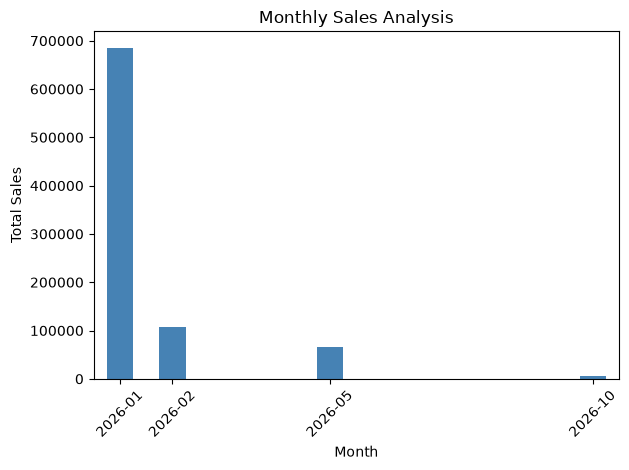

In [194]:
monthly_sales.plot(
    kind="bar",
    color= "steelblue"
)

plt.title("Monthly Sales Analysis")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

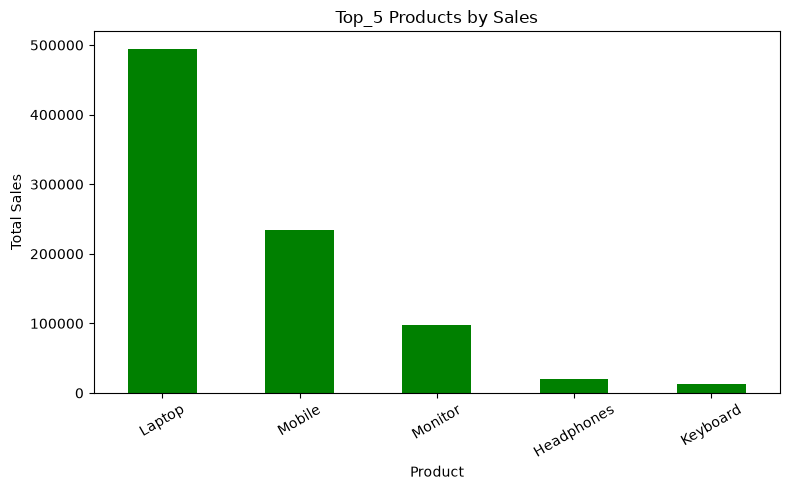

In [200]:
Top_5 = (
    df.groupby("Product")["Sales"].sum()
    .sort_values(ascending=False)
    .head(5)
)

Top_5.plot(
    kind="bar",
    color="green",
    figsize=(8,5)
)

plt.title("Top_5 Products by Sales")
plt.xlabel("Product")
plt.ylabel("Total Sales")
plt.xticks(rotation = 30)
plt.tight_layout()
plt.show()

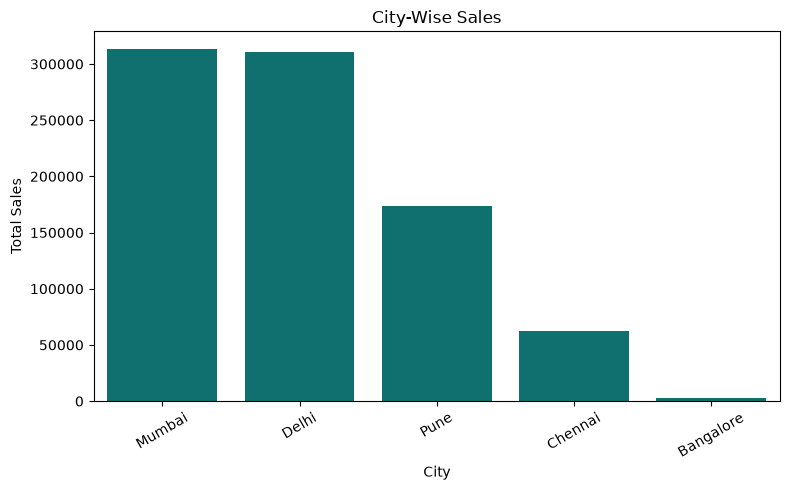

In [205]:
City_Sales = (
    df.groupby("City")["Sales"].sum().sort_values(ascending=False)
)

plt.figure(figsize=(8,5))
sns.barplot(
    x= City_Sales.index,
    y= City_Sales.values,
    color="teal"
)

plt.title("City-Wise Sales")
plt.xlabel("City")
plt.ylabel("Total Sales")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

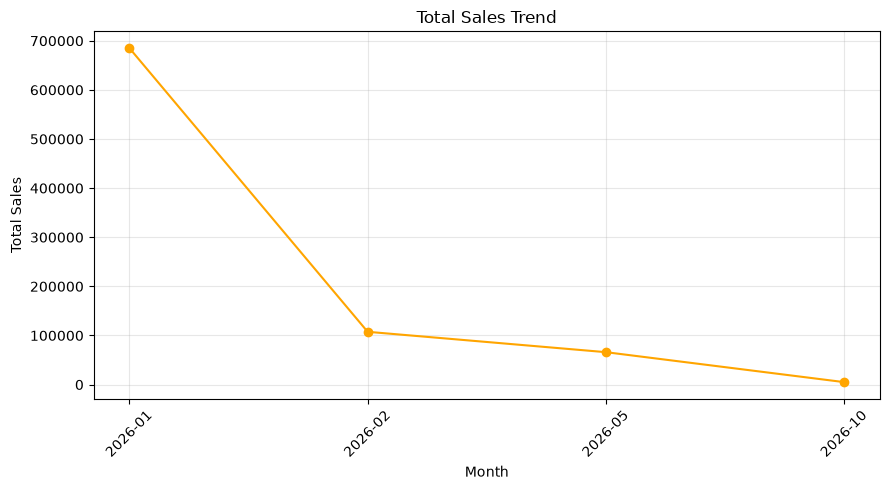

In [212]:
monthly_sales = (
    df.groupby("Month")["Sales"]
    .sum()
    .sort_index()
)

monthly_sales.index = monthly_sales.index.astype(str)

plt.figure(figsize=(9,5))
plt.plot(
    monthly_sales.index,
    monthly_sales.values,
    marker ="o",
    color= "orange"
)

plt.title("Total Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Sales")
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

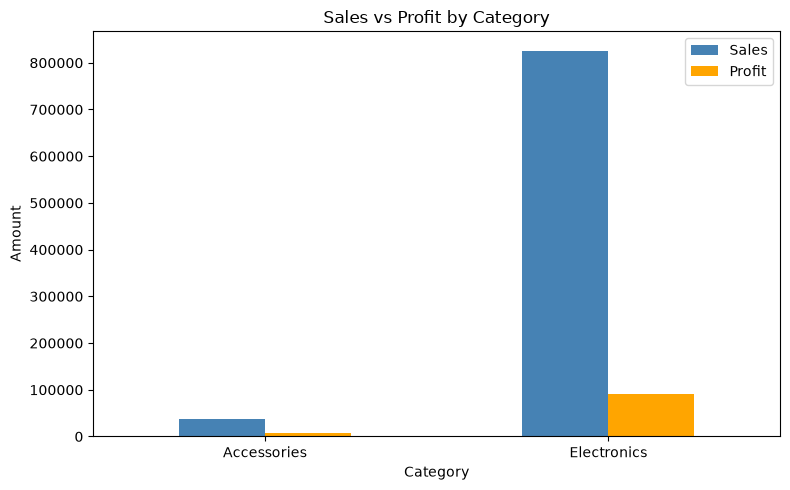

In [214]:
summary = df.groupby("Category")[
    ["Sales", "Profit"]
].sum()

summary.plot(
    kind="bar",
    figsize=(8, 5),
    color=["steelblue", "orange"]
)

plt.title("Sales vs Profit by Category")
plt.ylabel("Amount")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()
